# Performing a Multivariate Regression

*Section 5 — Regression, notebook 5 of 6.* Previous: `04_multiple_linear_regression`. Next: `06_compare_regressors`.

**You will learn:**

- how to tune the hyper-parameters of an Extra Trees regressor with `rsgispy.regression.regsklearn.perform_sklearn_regressor_param_search`;
- how to assess a multivariate model with a repeated k-fold cross-validation (`perform_kfold_fit` and `summarise_kfold_metrics`);
- how to check its residuals for bias and normality with `plot_pred_vs_obs`, `plot_residuals` and `plot_qq_residuals` from `rsgispy.regression.regmetrics`;
- how to fit and save the final model with `train_sklearn_regressor`;
- how to apply a multi-output model to an image with `apply_sklearn_regressor` and map the three outputs.

**Before you start:** notebooks 1-4 explain the data and the feature selection; nothing from them needs to have been run.

**Data:** `../data/lidar/Forest_Plot_Metrics_LassoLars_Sel.csv`, `../data/lidar/regrs_opt_params_et.json`, `../data/lidar/Forest_ALS_Metrics.tif` and `../data/lidar/Forest_ALS_Valid.tif`.

**Run time:** about 1 minute.

## Overview

The regression analysis we have applied in the other notebooks treats each dependent variable independently, with a different model for each. However, such an approach does not preserve the covariance/correlations between these dependent variables, therefore we should use multivariate regression to predict all three response variables simultaneously. To undertake this analysis, we will use the "Extra Trees Regressor" from the scikit-learn library but we could also use other regressors such as:

 1. Ordinary Least Squares Linear regressor
 2. Partial Least Squares (PLS) regressor
 3. Elastic Net regressor
 4. Kernel Ridge regressor
 5. k-Nearest Neighbours regressor
 6. Extra Trees regressor

# 1. Imports

In [1]:
import os

import pandas
import rsgispy.regression.regsklearn as rsk
import scipy.stats
import sklearn.model_selection
from rsgispy.imageutils.masking import ImageBandInfo
from rsgispy.imageutils.metadata import get_band_names
from rsgispy.mapping.layout import MapPanel, create_map_panels
from rsgispy.regression.regmetrics import plot_pred_vs_obs, plot_qq_residuals, plot_residuals
from rsgispy.tools.jsonio import read_json_to_dict
from sklearn.ensemble import ExtraTreesRegressor

In [2]:
%matplotlib inline

# 2. Read the input plot data 

In [3]:
# Open the CSV file as a Pandas data frame - the df variable.
df = pandas.read_csv("../data/lidar/Forest_Plot_Metrics_LassoLars_Sel.csv", index_col=0)

# Get a list of the columns within the df dataframe
cols = list(df.columns)

# Get the indepedent predictor column names
ind_vars = cols[6:]

# Get the dependent response column names
dep_vars = cols[3:6]

# 3. Create output directory

In [4]:
# All the files created by this notebook are written to the outputs directory.
out_dir = os.path.join("outputs", "et_multivar_reg_outputs")
os.makedirs(out_dir, exist_ok=True)

# 4. Performing a grid-search for optimal hyper-parameters

Before we can perform the regression analysis, we must tune our models to ensure that we are using the optimal hyper-parameters. The optimal hyper-parameters are specific to each algorithm and will vary depending on the training data.

A grid-search is one popular method of identifying the optimal hyper-parameters. In an exhaustive grid search, a matrix of all possible parameter combinations is generated (e.g. using latin hypercube sampling). Each parameter combination is then tested and accuracy metrics are computed (using cross-validation) to determine how well the model was able to fit the training data. We can identify the best hyper-parameters by finding the parameter combinations that have produced the highest accuracy scores (or lowest errors).

A grid search can take a long time (e.g., several hours) when we want to test all possible hyper-parameter combinations on a large training dataset (e.g., > 100,000 samples). To speed up the process, we can randomly sample the parameter grid rather than test all possible parameter combinations. This approach is less accurate than performing an exhaustive search.

To find the optimal parameters the following steps needs to be undertaken, example given using the ExtraTreesRegressor algorithm. 

## 4.1 Read the field plot data in using Pandas as we’ve done in the other scripts

*Already done*

## 4.2 Split out the dependent and predictor variables from the dataframe



In [5]:
# Get the predictor variables and dependent variables
# from the dataframe as numpy arrays
x = df[ind_vars].values
y = df[dep_vars].values

## 4.3 Define the ExtraTreesRegressor and the parameters to be searched

The parameter grid is a dict with a list of values to test for each hyper-parameter of the regressor.

> **RSGISLib users:** `rsgislib.regression.regresssklearn.get_et_obj_params` returned the regressor, a parameter grid and whether to scale the data. In rsgispy you define the regressor and the grid yourself, or get rsgispy's standard grid for a regressor with `rsk.get_sklearn_regressor_param_space(ExtraTreesRegressor())`.

In [6]:
# Create the Extra Trees Regressor object
regrs_obj = ExtraTreesRegressor(random_state=0)

# Define the grid of parameters to be searched
regrs_params = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 10, None],
    "max_features": [3, 6, 9, 12],
    "min_samples_split": [2, 4, 8],
    "min_samples_leaf": [1, 2, 4],
}

## 4.4 Rescaling the data

Some regressors (e.g., k-nearest neighbours or kernel ridge) need the predictor variables to be on the same scale, for example with the scikit-learn StandardScaler (https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html), which standardizes features by removing the mean and scaling to unit variance. Tree-based regressors such as Extra Trees split on one variable at a time and do not need scaling, so it is not used here; notebook 6 shows how to add a scaler to a regressor with a scikit-learn `Pipeline`.


## 4.5 Get a subset of the data

Parameter optimisation is computationally expensive so we cannot use the full datasets.


In [7]:
# Randomly sample the input data to create training and testing (20% sample) datasets
# so we have an independent dataset to test the quality of the relationship
df_train, df_test = sklearn.model_selection.train_test_split(df, test_size=0.2, random_state=0)

# Split the training data to have a subset for optimising the parameters.
# Using a subset significantly speeds up this analysis.
df_data, df_opt_data = sklearn.model_selection.train_test_split(
    df_train, test_size=0.3, random_state=0
)
print("{} samples for the parameter search".format(len(df_opt_data)))

40 samples for the parameter search


## 4.6 Perform the parameter search and save those 'best' parameters for future use

`perform_sklearn_regressor_param_search` takes a table of samples with the predictor (`feature_cols`) and response (`target_cols`) columns. With `search_method="grid"` every combination in the grid is tested (here 3 x 4 x 4 x 3 x 3 = 432 combinations, each fitted once per cross-validation fold), which can take a long time. To keep this notebook quick, a random search (`search_method="random"`) tests just `n_iter=10` randomly selected combinations with a 2-fold cross-validation. The best parameters are saved to a JSON file.

> **RSGISLib users:** this replaces `create_search_obj` and `perform_search_param_opt`. A `GridSearchCV` / `RandomizedSearchCV` object can still be passed as the regressor if you prefer to make your own.

In [8]:
# Perform the parameter search
opt_params_file = os.path.join(out_dir, "regrs_opt_params_et.json")
skl_regrs_opt_obj = rsk.perform_sklearn_regressor_param_search(
    None,
    regrs_obj,
    df_opt_data,
    target_cols=dep_vars,
    feature_cols=ind_vars,
    param_space=regrs_params,
    search_method="random",
    n_iter=10,
    cv=2,
    n_jobs=2,
    rnd_seed=0,
    out_params_json=opt_params_file,
)
read_json_to_dict(opt_params_file)

{'best_params': {'max_depth': 5,
  'max_features': 12,
  'min_samples_leaf': 2,
  'min_samples_split': 2,
  'n_estimators': 100},
 'best_score': 0.5171765554790185,
 'param_space_mode': 'custom',
 'scoring': 'r2',
 'search_method': 'random',
 'target_cols': ['Mean DBH', 'BA / ha', 'Vol / ha']}

# 5. Regression analysis with k-fold cross-validation

Having found the optimal hyper-parameters for each machine learning algorithm, we can proceed with the regression analysis. Since we lack independent test data to evaluate each regression model, **resampling methods** must be employed to evaluate the **accuracy** and **precision** of each model:

![Regression Fitting Methods](figures/regression_fitting_methods.png)

In this tutorial, we will use the train-test split method, with 80% of the forest inventory plots used for training and 20% for validation. Here is a summary of the procedure:

 * randomly shuffle the data to remove any ordering,
 * split the data into training and test partitions (80% training, 20% test),
 * fit the regressor on the training sample and then generate predictions for the test sample,
 * calculate accuracy statistics to measure the prediction error on the test sample.

This description illustrates just one iteration of the train-test split. However, if we want to evaluate the **precision** (i.e., stability) of the regression model, we must perform **several replicates** of the train-test split. By performing several iterations/replicates, **we can evaluate how robust the regression model is to sampling variations**.

Note. By performing several iterations/replicates of the cross-validation procedure, we are **attempting to mimic the variability that would exist if several independent forest inventories were collected in our study region** (i.e. we would expect the training data to differ between separate forest inventories due to sampling variations).

A model that is overfitted to the training data will have a high bias, whereas a model that is underfitted will have high variance. The optimal model will generate unbiased predictions whilst also being robust to variations in the training data (bias-variance tradeoff).


## 5.1 Read the Optimised Parameters from file
So that your results match those in this notebook, we use the optimised parameters provided in `../data/lidar/regrs_opt_params_et.json`, which were found with a larger search. To use the parameters you have just found instead, read `opt_params_file` (the `best_params` entry).

In [9]:
# Read in the optimised parameters for the Extra Trees Model
opt_params_file = "../data/lidar/regrs_opt_params_et.json"
skregrs_params = read_json_to_dict(opt_params_file)
skregrs_params

{'max_depth': 5,
 'max_features': 9,
 'min_samples_leaf': 1,
 'min_samples_split': 4,
 'n_estimators': 100}

## 5.2 Create the Instanace with the parameters for the Regressor

In [10]:
skregrs_obj = ExtraTreesRegressor(**skregrs_params, random_state=0)

## 5.3 Perform a k-fold Model Fit

`rsgispy.regression.regsklearn.perform_kfold_fit` assesses a scikit-learn regressor with a repeated k-fold cross-validation (scikit-learn's `RepeatedKFold`). In each repeat the plots are split at random into `n_splits` folds, and each fold is predicted by a copy of the regressor fitted to the other folds; the accuracy of each fold is calculated with `rsgispy.regression.regmetrics.calc_reg_metrics`. It returns two dicts keyed by the dependent variable: `metrics`, a DataFrame with a row of metrics for each fold (r2, rmse, mae, bias, explained_variance, pearson_r, mse, and the normalised RMSE and bias as a percentage of the mean, nrmse and nbias, and of the range, nrmse_range), and `residuals`, a DataFrame of the observed (`y_true`) and predicted (`y_pred`) values of all the folds. The random splits are fixed by `rnd_seed`.

> **RSGISLib users:** this replaces `rsgislib.regression.regresssklearn.perform_kfold_fit`. Instead of a `data_scaler` argument, put a scaler and the regressor in a scikit-learn `Pipeline` (see notebook 6), so the scaler is fitted to the training folds only. RSGISLib also reported the median absolute error and a bias-variance decomposition, which are not calculated.

In [11]:
# 5 folds, repeated 20 times = 100 model fits. With out_dir, the metrics and
# residuals of each dependent variable are also written to CSV files.
metrics, residuals = rsk.perform_kfold_fit(
    skregrs_obj,
    x,
    y,
    dep_vars,
    n_splits=5,
    n_repeats=20,
    rnd_seed=0,
    out_dir=out_dir,
    out_prefix="kfold_et",
)

  0%|          | 0/100 [00:00<?, ?it/s]

## 5.4 Export Metrics and Residuals

The metrics and residuals were written to CSV files in `out_dir` by `perform_kfold_fit`, with the dependent variable name in lower case, without spaces or punctuation:

In [12]:
sorted(f for f in os.listdir(out_dir) if f.startswith("kfold_et"))

['kfold_et_metrics_ba_ha.csv',
 'kfold_et_metrics_mean_dbh.csv',
 'kfold_et_metrics_vol_ha.csv',
 'kfold_et_residuals_ba_ha.csv',
 'kfold_et_residuals_mean_dbh.csv',
 'kfold_et_residuals_vol_ha.csv']

## 5.5 Summarise Metrics

The next step is to summarise the metrics we have just calculated, with `rsk.summarise_kfold_metrics`, so we can try and understand the quality of the results and if we had run multiple regression algorithms then which had provided the best results. 

For this analysis we want to summarise each individual set of outputs for each of the dependent variable. The metrics we will focus on are:

 1. The coefficient of determination (r2),
 2. Root Mean Square Error (RMSE),
 3. Bias.

**Note**. *The plot data are randomly shuffled to create the folds. The shuffles are fixed by `rnd_seed` so the results are the same each time you run the notebook; try a different seed to see how much the metrics change.*


As the name implies, the RMSE is the square root of the mean squared errors between our predicted and observed response variables:

$
\text{RMSE} = \sqrt{\sum_{i=0}^{n}{\frac{(\hat{y}_{i} - y_{i})^{2}}{n}}}
$

RMSE quantifies the quadratic mean error of our regression model in the same units of measurement as our original data. For example, for the Extra Trees regressor, the median RMSE for mean DBH was 3.3 cm, whilst the RMSE for basal area was 7.4 m2 ha-1.


To compare RMSE values across variables with different measurement units, we can normalise the RMSE into a percentage error by dividing the RMSE by the mean of the response variable and then multiplying by 100:

$
n\text{RMSE} (\%) = 100 \times \frac{\text{RMSE}}{\bar{y}} 
$

We can now easily compare the RMSE values across all of our response variables, for example for ET:
 * nRMSE of mean DBH = 19.2%
 * nRMSE of basal area per hectare = 20.8%
 * nRMSE of stem volume per hectare = 20.9%.

The bias of an estimator is another important accuracy measure. It is simply the mean difference between our predicted and observed response variables:

$
\text{Bias} = \sum_{i=1}^{n}\frac{\hat{y}_{i} - y_{i}}{n}
$

Like RMSE, bias is quantified in the same measurement units as our original data. However, bias can be positive or negative. Negative bias indicates that our model is, on average, underestimating the true values in our response variables. Conversely, positive bias indicates that our model is overestimating the true/observed values in our response variables.

An unbiased estimator (bias = zero) is preferable to a biased model (bias not zero), however biased estimators are frequently used when:
 1. an unbiased estimator is not available, or
 2. a biased estimator gives significantly lower RMSE or higher r2 values.

To allow bias values to be compared across variables with different measurement units, we can normalise the absolute bias into a percentage by dividing the bias by the mean of the response variable and then multiplying by 100:

$
n\text{Bias} (\%) = 100 \times \frac{Bias}{\bar{y}} 
$


In [13]:
# The mean, median, standard deviation and 5th and 95th percentiles of
# each metric over the 100 folds, for each dependent variable.
kfold_summary = rsk.summarise_kfold_metrics(metrics)
kfold_summary.to_csv(os.path.join(out_dir, "kfold_et_summary.csv"))
for dep_var in dep_vars:
    print(dep_var)
    print(kfold_summary.loc[dep_var].round(3))
    print()

Mean DBH
                      mean  median    std     p05     p95
metric                                                   
r2                   0.709   0.730  0.098   0.537   0.840
rmse                 3.374   3.286  0.798   2.279   4.890
mae                  2.338   2.318  0.420   1.690   3.023
bias                -0.034   0.074  0.806  -1.440   1.220
explained_variance   0.726   0.747  0.098   0.553   0.853
pearson_r            0.858   0.873  0.059   0.748   0.925
mse                 12.017  10.798  5.693   5.193  23.909
nrmse               19.594  19.195  4.010  13.928  26.332
nrmse_range         12.875  12.719  2.288   9.436  16.552
nbias               -0.015   0.401  4.673  -7.767   7.216

BA / ha
                      mean  median     std     p05     p95
metric                                                    
r2                   0.838   0.844   0.050   0.731   0.905
rmse                 7.380   7.418   1.070   5.728   9.125
mae                  5.485   5.421   0.796   4.337

## 5.6. Plot Residuals

A residual plot is a useful method of visually investigating the distribution of errors in our regression model. We can use the residual plot to investigate both the normality and homoscedasticity of the model errors.


First, a plot of the predicted against the observed values of all the folds, with the 1:1 line, shows how well the model fits each variable. `plot_pred_vs_obs` (and `plot_residuals` and `plot_qq_residuals`) from `rsgispy.regression.regmetrics` take a table with the observed and predicted values, here with one pair of columns for each variable, and return the Matplotlib figure and axes:

> **RSGISLib users:** `rsgislib.tools.plotting.residual_plot` is replaced by `plot_residuals`, which plots the residuals against the predicted values with a histogram of the residuals; `plot_qq_residuals` (section 5.7) draws the Q-Q plots.

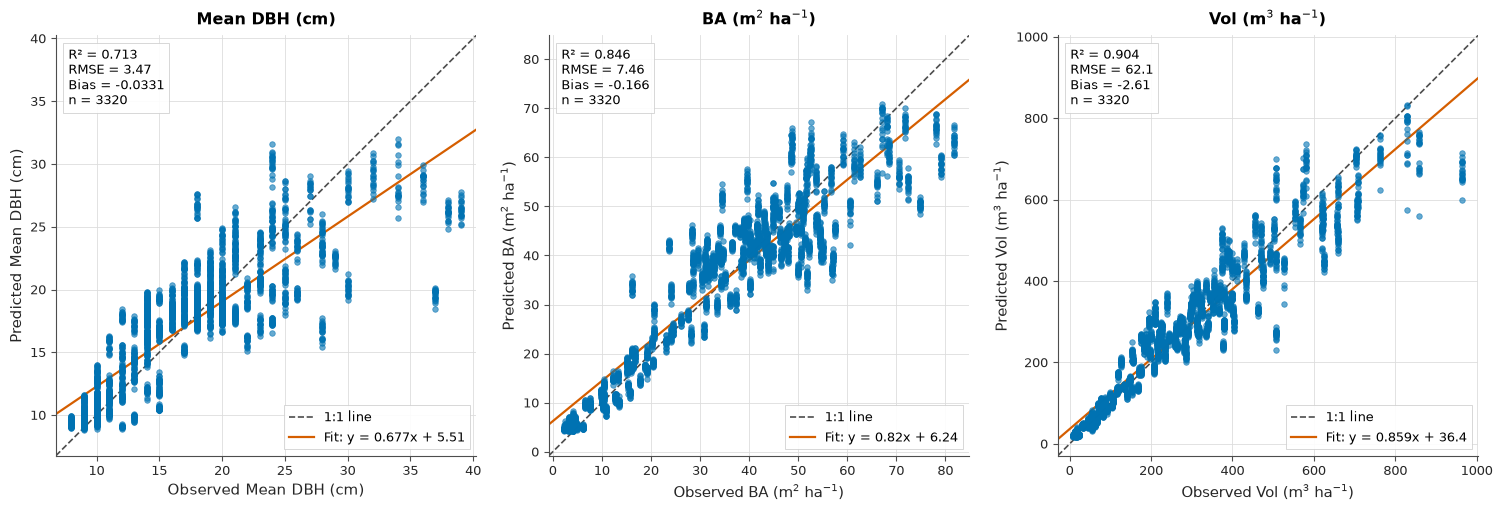

In [14]:
# Join the observed and predicted values of the three variables into one table.
pred_obs_df = pandas.DataFrame()
for i, dep_var in enumerate(dep_vars):
    pred_obs_df["obs_{}".format(i)] = residuals[dep_var]["y_true"]
    pred_obs_df["pred_{}".format(i)] = residuals[dep_var]["y_pred"]
obs_cols = ["obs_{}".format(i) for i in range(len(dep_vars))]
pred_cols = ["pred_{}".format(i) for i in range(len(dep_vars))]
# The names of the variables (in the order of dep_vars), with units, for the plots.
plot_names = ["Mean DBH (cm)", "BA (m$^2$ ha$^{-1}$)", "Vol (m$^3$ ha$^{-1}$)"]

fig, axs = plot_pred_vs_obs(
    pred_obs_df,
    ref_cols=obs_cols,
    pred_cols=pred_cols,
    target_names=plot_names,
    out_plot_file=os.path.join(out_dir, "et_pred_vs_obs.png"),
)

Then the residuals (predicted - observed) of each variable against the predicted values, with a histogram of the residuals (and the normal distribution with the same mean and standard deviation) beside each plot:

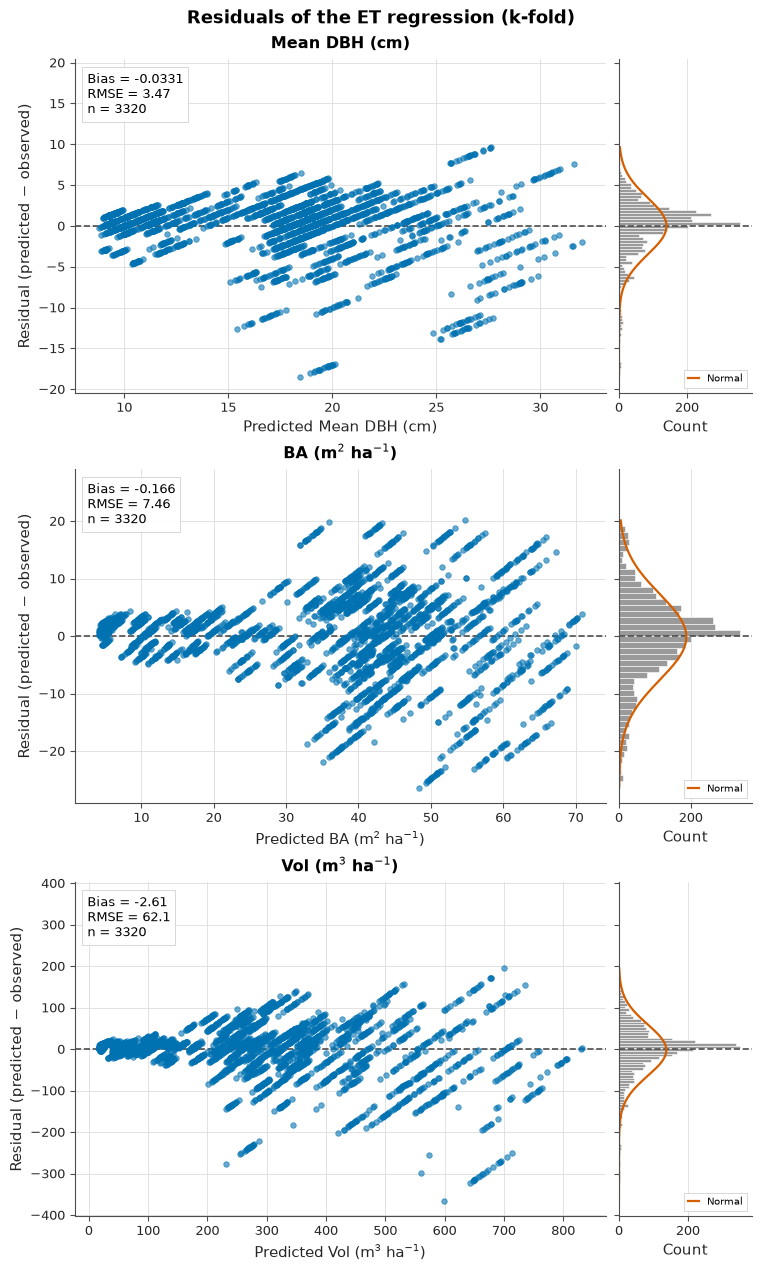

In [15]:
fig, axs = plot_residuals(
    pred_obs_df,
    ref_cols=obs_cols,
    pred_cols=pred_cols,
    target_names=plot_names,
    title="Residuals of the ET regression (k-fold)",
    out_plot_file=os.path.join(out_dir, "et_residuals_plot.png"),
)

From these plots we can see that there is a clear trend in our residuals which indicates that our ET model is underestimating plots with larger values: in the predicted against observed plots the points for the larger plots fall below the 1:1 line and the fitted line is flatter than the 1:1 line. For example, for plots with a stem volume > 600 m3 ha-1 there is a clear underestimation. If we were to investigate this further, it is likely that we would find that there are a small number of plots with high stem volume and therefore the training data has not well sampled these plots so the model is not well fitted to these plots. If it would possible, we could look to increase the number of these plots within our training dataset.

*Note. each plot is predicted 20 times (once in each repeat of the k-fold), with slightly different models, so it appears in the residual plots as a short diagonal line of points.*

## 5.7 Investigating the normality of residuals

A quantile-quantile plot is a useful method of visually investigating whether the errors/residuals from our model follow a normal (Gaussian) distribution: the ordered residuals are plotted against the quantiles of a normal distribution, so normally distributed residuals fall on a straight line.

`plot_qq_residuals` from `rsgispy.regression.regmetrics` draws a Q-Q plot of the residuals of each variable (with `scipy.stats.probplot`), with the fitted line and the result of the Shapiro-Wilk test (see below). For any other values, `rsgispy.tools.plotting.plot_qq` draws a Q-Q plot of an array. The code below generates the Q-Q plots of the residuals for mean DBH, basal area and stem volume per hectare for the Extra Trees model:

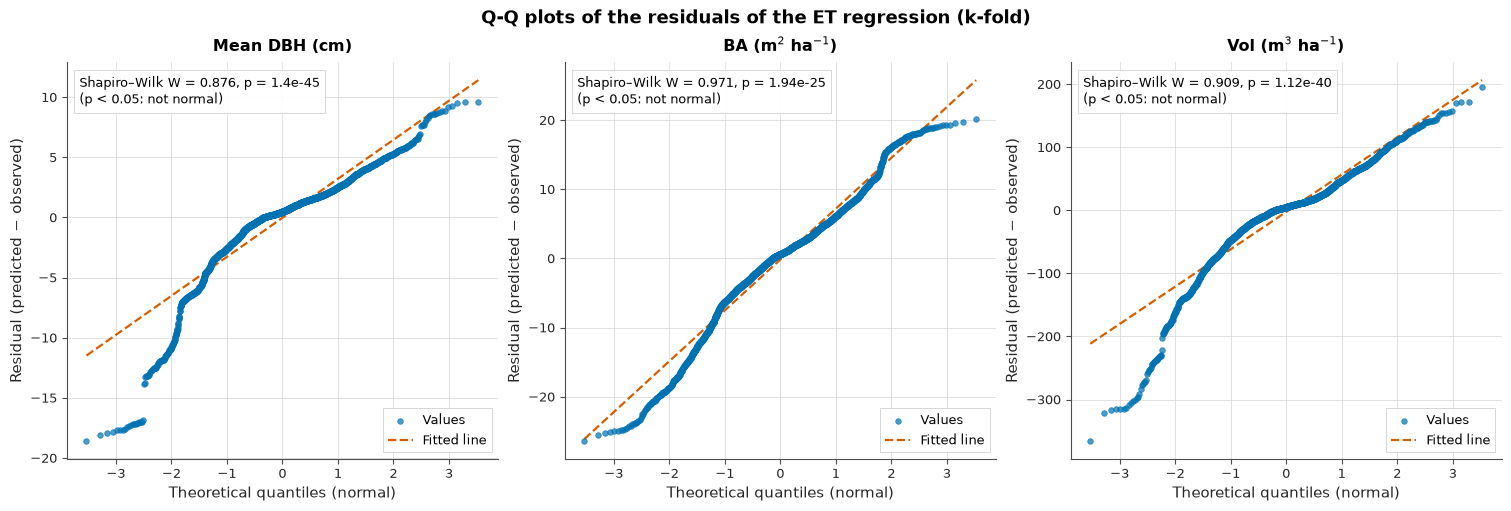

In [16]:
fig, axs = plot_qq_residuals(
    pred_obs_df,
    ref_cols=obs_cols,
    pred_cols=pred_cols,
    target_names=plot_names,
    title="Q-Q plots of the residuals of the ET regression (k-fold)",
    out_plot_file=os.path.join(out_dir, "et_residuals_qq_plots.png"),
)

The Q-Q plots demonstrate that our residuals deviate from a normal distribution (the points would follow the dashed fitted line). This is especially noticeable in the lower tail for DBH and stem volume: a small number of plots have large negative residuals, i.e., they are underestimated, as we saw above.

To test the significance of these deviations from normality, we can use several functions available in SciPy:
 * Shapiro-Wilk Test - scipy.stats.shapiro()
 * Kolmogorov-Smirnov Test - scipy.stats.kstest()
 * Anderson-Darling Test - scipy.stats.anderson()

The Shapiro-Wilk test, shown on the Q-Q plots above, can also be run directly:

In [17]:
# The residuals (predicted - observed) of each variable.
ba_residuals = residuals["BA / ha"]["y_pred"].values - residuals["BA / ha"]["y_true"].values
dbh_residuals = residuals["Mean DBH"]["y_pred"].values - residuals["Mean DBH"]["y_true"].values
vol_residuals = residuals["Vol / ha"]["y_pred"].values - residuals["Vol / ha"]["y_true"].values

In [18]:
w, pval = scipy.stats.shapiro(ba_residuals)
print("ba: W = {}, p = {}".format(round(w, 4), round(pval, 4)))
if pval > 0.05:
    print(
        "Accept the null hypothesis that the residuals are Gaussian at the 95% confidence interval (ba)"
    )
else:
    print(
        "Reject the null hypothesis that the residuals are Gaussian at the 95% confidence interval (ba)"
    )

ba: W = 0.9709, p = 0.0
Reject the null hypothesis that the residuals are Gaussian at the 95% confidence interval (ba)


In [19]:
w, pval = scipy.stats.shapiro(dbh_residuals)
print("dbh: W = {}, p = {}".format(round(w, 4), round(pval, 4)))
if pval > 0.05:
    print(
        "Accept the null hypothesis that the residuals are Gaussian at the 95% confidence interval (dbh)"
    )
else:
    print(
        "Reject the null hypothesis that the residuals are Gaussian at the 95% confidence interval (dbh)"
    )

dbh: W = 0.8755, p = 0.0
Reject the null hypothesis that the residuals are Gaussian at the 95% confidence interval (dbh)


In [20]:
w, pval = scipy.stats.shapiro(vol_residuals)
print("vol: W = {}, p = {}".format(round(w, 4), round(pval, 4)))
if pval > 0.05:
    print(
        "Accept the null hypothesis that the residuals are Gaussian at the 95% confidence interval (vol)"
    )
else:
    print(
        "Reject the null hypothesis that the residuals are Gaussian at the 95% confidence interval (vol)"
    )

vol: W = 0.9093, p = 0.0
Reject the null hypothesis that the residuals are Gaussian at the 95% confidence interval (vol)


`scipy.stats.shapiro` returns the test statistic (W) and the p-value. Our p-values are less than 0.05, therefore we reject the null hypothesis and accept the alternative hypothesis that the residuals are non-Gaussian at the 95% confidence interval. If the p-value was > 0.05, we would accept the null hypothesis that the residuals are Gaussian. Note that with this many residuals (166 plots x 20 repeats) the test detects even small departures from normality, so look at the Q-Q plots as well as the p-values.

> **RSGISLib users:** the RSGISLib version of this notebook read the outputs of `shapiro` the wrong way round (`pval, w = ...`), so it reported the W statistic as the p-value.

# 6. Creating the Final Model

We are now ready to apply our model to the image data, the first step is to build the final model and save it for future analysis. To save a scikit-learn model we commonly use the joblib module (which `rsgispy.regression.regsklearn` uses to save and load models) as recommended by the scikit-learn documentation: https://scikit-learn.org/stable/modules/model_persistence.html. It should be noted that when you’ve saved a model with the joblib module, that model might not be able to be loaded with other versions of scikit-learn depending on what changes occur within the scikit-learn library. You also need to be using the same version of Python, for example if you save the model with Python 3.7 and then try and open it with 3.8 or 3.9 it most likely will not work!


## 6.1 Read the Optimised Parameters File

In [21]:
# Read in the optimised parameters for the Extra Trees Model
opt_params_file = "../data/lidar/regrs_opt_params_et.json"
skregrs_params = read_json_to_dict(opt_params_file)
skregrs_params

{'max_depth': 5,
 'max_features': 9,
 'min_samples_leaf': 1,
 'min_samples_split': 4,
 'n_estimators': 100}

## 6.2 Fit the Model and Save it to File

`train_sklearn_regressor` fits the regressor to all the plots (the `feature_cols` predictors and the `target_cols` responses of the table), saves it to a `.joblib` file and returns the fitted model and its accuracy on the training data. With `test_data` and `valid_data` tables it also reports the accuracy on those samples. The `train_` metrics without a variable name are the mean of the three variables, which is not meaningful for variables with different units, so look at the per-variable values.

In [22]:
# Output model file
output_mdl_file = os.path.join(out_dir, "Forest_Reg_ET_Model.joblib")

skregrs_obj, train_metrics = rsk.train_sklearn_regressor(
    None,
    ExtraTreesRegressor(**skregrs_params, random_state=0),
    df,
    target_cols=dep_vars,
    feature_cols=ind_vars,
    out_model_file=output_mdl_file,
    return_model=True,
)
# Print the training accuracy of each variable
{key: round(val, 3) for key, val in train_metrics.items() if any(var in key for var in dep_vars)}

{'train_Mean DBH_r2': 0.807,
 'train_Mean DBH_rmse': 2.841,
 'train_Mean DBH_mae': 1.933,
 'train_Mean DBH_bias': -0.0,
 'train_Mean DBH_explained_variance': 0.807,
 'train_Mean DBH_pearson_r': 0.902,
 'train_BA / ha_r2': 0.918,
 'train_BA / ha_rmse': 5.448,
 'train_BA / ha_mae': 4.063,
 'train_BA / ha_bias': -0.0,
 'train_BA / ha_explained_variance': 0.918,
 'train_BA / ha_pearson_r': 0.959,
 'train_Vol / ha_r2': 0.968,
 'train_Vol / ha_rmse': 35.542,
 'train_Vol / ha_mae': 26.004,
 'train_Vol / ha_bias': -0.0,
 'train_Vol / ha_explained_variance': 0.968,
 'train_Vol / ha_pearson_r': 0.985}

## 6.3 Check that the Saved Model loads...

You probably don't need this step but it can be useful to double check if it is a file you intend to reuse and come back to. 

In [23]:
# Verify that the model can be read from disk:
print("Attempting to read regression model from disk...")
regrs_test_mdl = rsk.load_sklearn_regressor(output_mdl_file)
regrs_test_mdl.predict(df[ind_vars])
print("Read model and used it predict successfully.")

Attempting to read regression model from disk...
Read model and used it predict successfully.


# 7. Apply Model to Image Data

To apply the model, we cannot use band maths as we did previously as the model is providing multiple outputs (i.e., 3). Therefore, we need to use the scikit-learn model directly. To do this we will use the `apply_sklearn_regressor` function from `rsgispy.regression.regsklearn`, which applies the model block by block and writes one output band for each response variable.

To ensure we are only applying the regression model to valid regions (i.e., pixel which are forest!) we provide a valid data mask (`Forest_ALS_Valid.tif`) alongside the LiDAR metrics image (`Forest_ALS_Metrics.tif`). The image bands to use are given with an `ImageBandInfo` object, listing the band numbers of the 12 metrics identified using the LassoLars feature selection method - **Note, these need to be the same and in the same order as used to train the regressor**. The image band numbering starts at 1.

> **RSGISLib users:** this replaces `apply_regress_sklearn_mdl`. The output bands are in the order of `target_cols` and named after them.

In [24]:
# Define Input Images
input_img = "../data/lidar/Forest_ALS_Metrics.tif"
vld_msk_img = "../data/lidar/Forest_ALS_Valid.tif"

In [25]:
# Image bands in the metrics image used by the model, found from the band
# names so they are in the same order as the model's predictor variables.
img_band_names = get_band_names(input_img)
metrics_band_idxs = [img_band_names.index(var) + 1 for var in ind_vars]
print(metrics_band_idxs)

img_band_info = [
    ImageBandInfo(input_img, name="als_metrics", bands=metrics_band_idxs, band_names=ind_vars)
]

[24, 27, 41, 42, 43, 46, 47, 48, 49, 51, 52, 61]


In [26]:
# Output Image
output_img = os.path.join(out_dir, "ALS_Forest_Estimates.tif")

# Apply the model to the image data; the output bands are in the order of
# dep_vars (Mean DBH, BA / ha, Vol / ha).
rsk.apply_sklearn_regressor(
    img_band_info,
    skregrs_obj,
    vld_msk_img,
    1,
    output_img,
    target_cols=dep_vars,
    gdalformat="GTIFF",
    out_no_data_val=0.0,
    calc_stats=True,
)
get_band_names(output_img)

  0%|          | 0/132 [00:00<?, ?it/s]

  0%|          | 0/132 [00:00<?, ?it/s]

  0%|          | 0/132 [00:00<?, ?it/s]

['Mean DBH', 'BA / ha', 'Vol / ha']

# 8. Visualise Results

You should now have the image `outputs/et_multivar_reg_outputs/ALS_Forest_Estimates.tif` created and you can open it in TuiView or QGIS. However, we can also make some maps using Python: `rsgispy.mapping.layout.create_map_panels` draws the three bands side by side, each as a `'cmap'` panel with a colour bar (as in notebooks 3 and 4).


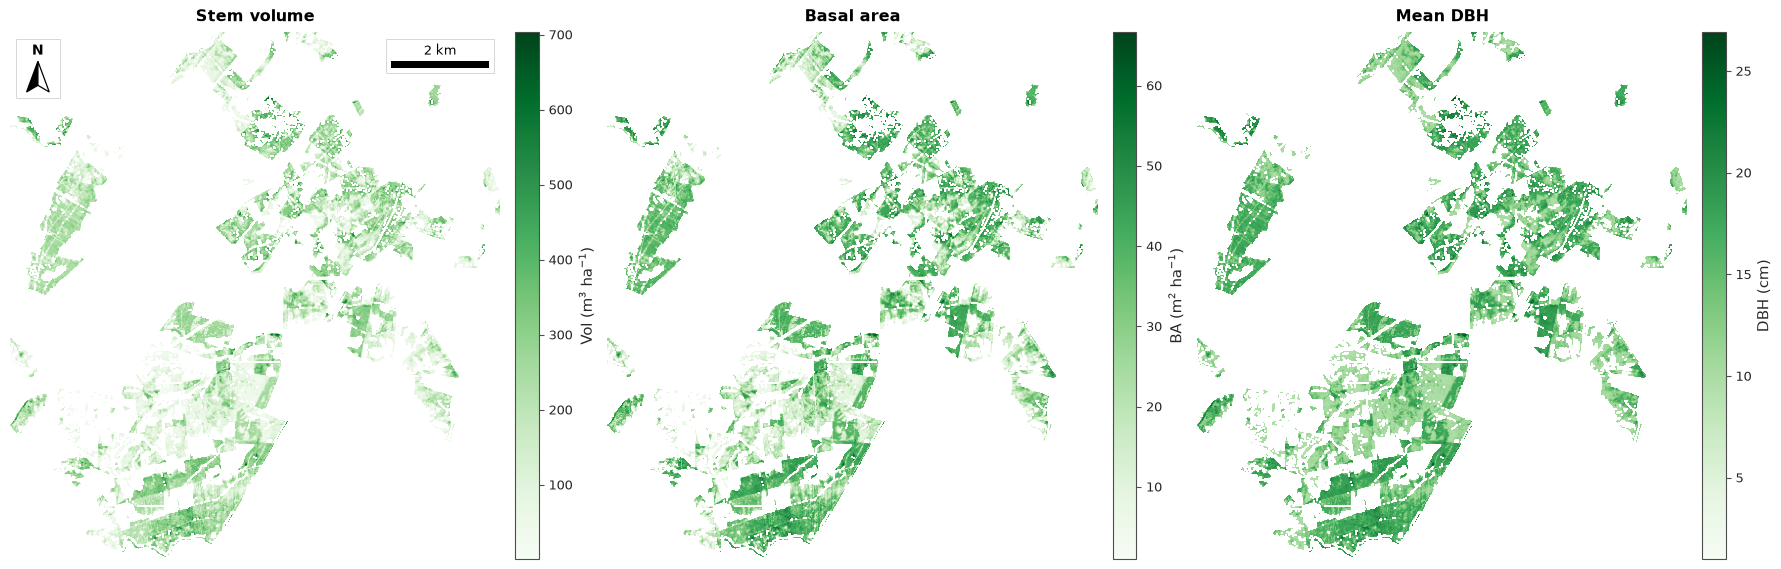

In [27]:
sub_bbox = [291171, 301190, 246680, 257452]

map_info = [
    # (band, title, colour bar label)
    (dep_vars.index("Vol / ha") + 1, "Stem volume", "Vol (m$^3$ ha$^{-1}$)"),
    (dep_vars.index("BA / ha") + 1, "Basal area", "BA (m$^2$ ha$^{-1}$)"),
    (dep_vars.index("Mean DBH") + 1, "Mean DBH", "DBH (cm)"),
]
# One 'cmap' panel with a colour bar for each band of the output image;
# values below vmin (no data, 0) are shown in white.
panels = [
    MapPanel(
        "cmap",
        output_img,
        bands=band,
        title=title,
        cmap_name="Greens",
        vmin=1,
        show_colour_bar=True,
        cbar_label=label,
        map_kw={"vals_under_white": True},
    )
    for band, title, label in map_info
]
fig, axs = create_map_panels(panels, bbox=sub_bbox)